<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta9_g%C3%B6rev2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: Tesla T4


Renkli BMP  -> Çözünürlük: 1000x1000, Kanal: 3, Ham Piksel Verisi: 3,000,000 byte, Disk Boyutu: 3,000,054 byte (2.86 MB)
Gri BMP     -> Çözünürlük: 1000x1000, Kanal: 1, Ham Piksel Verisi: 1,000,000 byte, Disk Boyutu: 1,001,078 byte (0.95 MB)
Boyut Oranı (Renkli / Gri) : 3.00x


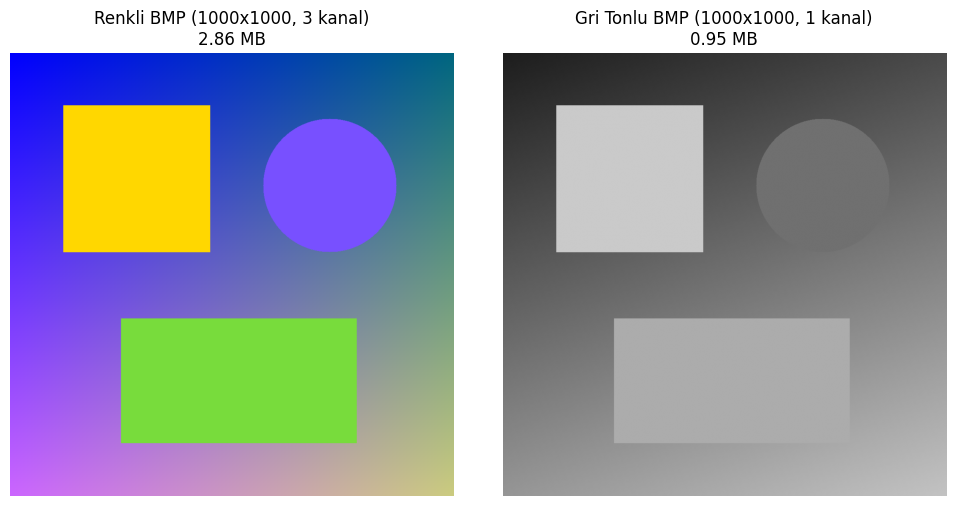

In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

color_bmp_path = "renkli_1000x1000.bmp"
gray_bmp_path = "gri_1000x1000.bmp"

canvas = np.zeros((1000, 1000, 3), dtype=np.uint8)

x_grid, y_grid = np.meshgrid(np.linspace(0, 255, 1000), np.linspace(0, 255, 1000))
canvas[:, :, 0] = (255 - x_grid * 0.5).astype(np.uint8)
canvas[:, :, 1] = ((x_grid + y_grid) * 0.4).astype(np.uint8)
canvas[:, :, 2] = (y_grid * 0.8).astype(np.uint8)

cv2.rectangle(canvas, (120, 120), (450, 450), (0, 215, 255), -1)
cv2.circle(canvas, (720, 300), 150, (255, 80, 120), -1)
cv2.rectangle(canvas, (250, 600), (780, 880), (60, 220, 120), -1)

cv2.imwrite(color_bmp_path, canvas)

img_color = cv2.imread(color_bmp_path, cv2.IMREAD_COLOR)
assert img_color is not None, "Renkli BMP dosyası açılamadı!"

img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)
cv2.imwrite(gray_bmp_path, img_gray)

color_size_bytes = os.path.getsize(color_bmp_path)
gray_size_bytes = os.path.getsize(gray_bmp_path)

h_c, w_c = img_color.shape[:2]
c_channels = img_color.shape[2] if img_color.ndim == 3 else 1

h_g, w_g = img_gray.shape[:2]
g_channels = img_gray.shape[2] if img_gray.ndim == 3 else 1

raw_color_bytes = h_c * w_c * c_channels * 1
raw_gray_bytes = h_g * w_g * g_channels * 1

print(f"Renkli BMP  -> Çözünürlük: {w_c}x{h_c}, Kanal: {c_channels}, Ham Piksel Verisi: {raw_color_bytes:,} byte, Disk Boyutu: {color_size_bytes:,} byte ({color_size_bytes / (1024*1024):.2f} MB)")
print(f"Gri BMP     -> Çözünürlük: {w_g}x{h_g}, Kanal: {g_channels}, Ham Piksel Verisi: {raw_gray_bytes:,} byte, Disk Boyutu: {gray_size_bytes:,} byte ({gray_size_bytes / (1024*1024):.2f} MB)")
print(f"Boyut Oranı (Renkli / Gri) : {color_size_bytes / gray_size_bytes:.2f}x")

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))
plt.title(f"Renkli BMP ({w_c}x{h_c}, {c_channels} kanal)\n{color_size_bytes / (1024*1024):.2f} MB")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_gray, cmap="gray", vmin=0, vmax=255)
plt.title(f"Gri Tonlu BMP ({w_g}x{h_g}, {g_channels} kanal)\n{gray_size_bytes / (1024*1024):.2f} MB")
plt.axis("off")

plt.tight_layout()
plt.show()